# Install dependencies and connect Google Drive

In [1]:

%pip install -q torch torchvision opencv-python-headless pandas matplotlib scikit-learn


In [2]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


# Import libraries and define paths

In [3]:

import torch
import torch.nn as nn
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.models import resnet18

PROJECT = Path("/content/drive/MyDrive/Component03")

VIDEO_DIR = PROJECT / "input_videos"

MODEL_PATH = (
    PROJECT / "accident_model_results" /
    "resnet18_best.pt"
)

OUTPUT_DIR = PROJECT / "video_accident_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Model exists:", MODEL_PATH.exists())

assert MODEL_PATH.exists(), "Trained ResNet18 weights not found!"


Device: cpu
Model exists: True


# Load your trained ResNet18

Load the model

In [4]:

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

class_to_idx = checkpoint["class_to_idx"]

print("Class mapping:", class_to_idx)

accident_idx = class_to_idx["accident"]

model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("ResNet18 loaded successfully!")


Class mapping: {'accident': 0, 'normal': 1}
ResNet18 loaded successfully!


# Define image preprocessing

In [ ]:

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing ready")


# Implement frame-by-frame video prediction

Video prediction function

In [6]:

def predict_video(video_path, sample_fps=2, batch_size=16):
    video_path = Path(video_path)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Unable to open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0:
        cap.release()
        raise ValueError("Invalid video FPS")

    stride = max(1, round(fps / sample_fps))

    samples = []
    timestamps = []
    frame_numbers = []

    # Read selected frames in their original order
    for frame_idx in range(0, total_frames, stride):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        success, frame = cap.read()

        if not success:
            continue

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = Image.fromarray(rgb)

        samples.append(eval_transform(image))
        timestamps.append(frame_idx / fps)
        frame_numbers.append(frame_idx)

    cap.release()

    if not samples:
        raise ValueError("No readable frames found")

    probabilities = []

    with torch.inference_mode():
        for start in range(0, len(samples), batch_size):
            batch = torch.stack(
                samples[start:start + batch_size]
            ).to(device)

            logits = model(batch)
            probs = torch.softmax(logits, dim=1)

            accident_probs = probs[:, accident_idx]
            probabilities.extend(
                accident_probs.cpu().numpy().tolist()
            )

    result = pd.DataFrame({
        "frame": frame_numbers,
        "timestamp_sec": timestamps,
        "accident_probability": probabilities
    })

    return result


# Test on one accident video

Select a video

In [7]:

accident_videos = sorted([
    p for p in VIDEO_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".mp4"
    and p.parent.name.lower() in ["accident", "accident02"]
])

print("Accident videos found:", len(accident_videos))

for i, path in enumerate(accident_videos):
    print(i, path.relative_to(VIDEO_DIR))

assert accident_videos, "No accident videos found"

video_index = 0
selected_video = accident_videos[video_index]

print("\nSelected video:", selected_video.name)


Accident videos found: 14
0 Accident/video_100.mp4
1 Accident/video_133.mp4
2 Accident/video_141.mp4
3 Accident/video_147.mp4
4 Accident/video_166.mp4
5 Accident/video_170.mp4
6 Accident/video_174.mp4
7 Accident/video_178.mp4
8 Accident/video_183.mp4
9 Accident/video_198.mp4
10 Accident/video_199.mp4
11 Accident/video_200.mp4
12 Accident/video_204.mp4
13 Accident/video_93.mp4

Selected video: video_100.mp4


# Run accident prediction

In [8]:

predictions_df = predict_video(
    selected_video,
    sample_fps=2
)

display(predictions_df.head(15))

print("Frames analysed:", len(predictions_df))
print(
    "Highest accident probability:",
    round(predictions_df["accident_probability"].max(), 4)
)

predictions_df.to_csv(
    OUTPUT_DIR / "sample_accident_predictions.csv",
    index=False
)


,frame,timestamp_sec,accident_probability
0,0,0.0,0.000305
1,15,0.5,0.000143
2,30,1.0,0.000068
3,45,1.5,0.000030
4,60,2.0,0.000015
5,75,2.5,0.000039
6,90,3.0,0.000049
7,105,3.5,0.000098
8,120,4.0,0.000150
9,135,4.5,0.000103


Frames analysed: 109
Highest accident probability: 1.0


# Visualize accident probability over time

Plot the accident timeline

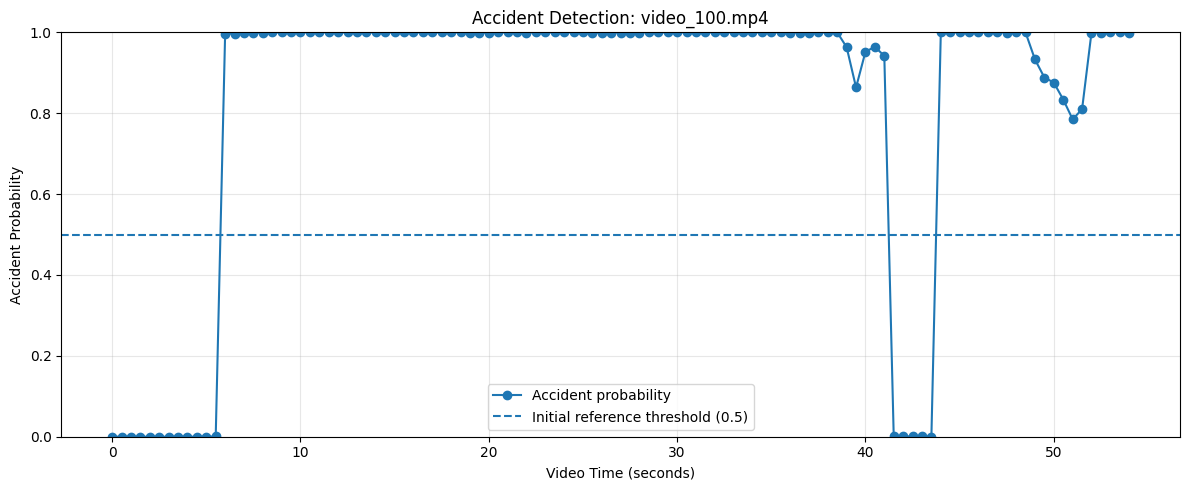

In [9]:

plt.figure(figsize=(12, 5))

plt.plot(
    predictions_df["timestamp_sec"],
    predictions_df["accident_probability"],
    marker="o",
    label="Accident probability"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Initial reference threshold (0.5)"
)

plt.xlabel("Video Time (seconds)")
plt.ylabel("Accident Probability")
plt.title(f"Accident Detection: {selected_video.name}")

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Build the basic video-level decision function

Temporal accident analysis

In [10]:

def analyze_accident_timeline(
    df,
    threshold=0.5,
    window=2
):
    df = df.sort_values(
        "timestamp_sec"
    ).copy().reset_index(drop=True)

    df["smoothed_probability"] = (
        df["accident_probability"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

    scores = df["smoothed_probability"].dropna()

    if scores.empty:
        return {
            "accident_detected": False,
            "peak_score": None,
            "estimated_time_sec": None
        }

    peak_idx = scores.idxmax()
    peak_score = float(scores.loc[peak_idx])
    peak_time = float(df.loc[peak_idx, "timestamp_sec"])

    return {
        "accident_detected": peak_score >= threshold,
        "peak_score": peak_score,
        "estimated_time_sec": (
            peak_time if peak_score >= threshold else None
        )
    }

# Preliminary test only
result = analyze_accident_timeline(
    predictions_df,
    threshold=0.5,
    window=2
)

print("Accident detected:", result["accident_detected"])
print("Peak score:", result["peak_score"])
print("Estimated event time:", result["estimated_time_sec"])


Accident detected: True
Peak score: 0.9999851584434509
Estimated event time: 29.0


# Select the best threshold using validation videos
We will use your existing video_splits.json and accident_intervals.csv.
For video-level labels:
- 1 means a video contains at least one verified accident interval.
- 0 means it contains no verified accident intervals.

We will evaluate thresholds from 0.20 to 0.80 and choose the one producing the highest validation macro F1-score. This is a small exploratory tuning exercise; with few validation videos, the chosen threshold may be unstable.

Run predictions on validation videos

In [11]:

import json
import pandas as pd

with open(PROJECT / "video_splits.json") as f:
    saved_splits = json.load(f)

intervals_df = pd.read_csv(
    PROJECT / "accident_intervals.csv"
)

intervals_df["label"] = (
    intervals_df["label"].str.strip().str.lower()
)

# Normalize path separators for matching
intervals_df["video"] = (
    intervals_df["video"].str.replace("\\", "/", regex=False)
)

validation_videos = saved_splits["val"]

validation_results = []

for relative_path in validation_videos:
    relative_path = relative_path.replace("\\", "/")
    video_path = VIDEO_DIR / relative_path

    if not video_path.exists():
        print("Missing video:", relative_path)
        continue

    rows = intervals_df[
        intervals_df["video"] == relative_path
    ]

    if rows.empty:
        print("Missing ground truth:", relative_path)
        continue

    actual_label = int(
        (rows["label"] == "accident").any()
    )

    frame_df = predict_video(video_path, sample_fps=2)

    analysis = analyze_accident_timeline(
        frame_df, threshold=0.5, window=2
    )

    validation_results.append({
        "video": relative_path,
        "actual": actual_label,
        "peak_score": analysis["peak_score"]
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

assert len(validation_df) == len(validation_videos), (
    "Some validation videos were not evaluated. "
    "Check path names and ground-truth intervals."
)


,video,actual,peak_score
0,Accident/video_198.mp4,1,0.723261
1,Accident/video_199.mp4,1,0.976726
2,Normal/20230818_acci-bg_123.mp4,0,0.142547
3,Normal/20230818_acci-bg_143.mp4,0,0.037325


Compare thresholds

In [16]:

import numpy as np
from sklearn.metrics import (
    f1_score, precision_score, recall_score
)

threshold_results = []

for threshold in np.arange(0.50, 0.81, 0.05):
    predicted = (
        validation_df["peak_score"] >= threshold
    ).astype(int)

    actual = validation_df["actual"]

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "macro_f1": f1_score(
            actual, predicted,
            average="macro", zero_division=0
        ),
        "accident_recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "accident_precision": precision_score(
            actual, predicted, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Primary: highest macro F1
# Tie-breaker: higher accident recall
threshold_df = threshold_df.sort_values(
    ["macro_f1", "accident_recall"],
    ascending=False
)

display(threshold_df)

BEST_THRESHOLD = float(
    threshold_df.iloc[0]["threshold"]
)

print("Selected threshold:", BEST_THRESHOLD)

threshold_df.to_csv(
    OUTPUT_DIR / "validation_threshold_comparison.csv",
    index=False
)


,threshold,macro_f1,accident_recall,accident_precision
0,0.50,1.000000,1.0,1.0
1,0.55,1.000000,1.0,1.0
2,0.60,1.000000,1.0,1.0
3,0.65,1.000000,1.0,1.0
4,0.70,1.000000,1.0,1.0
5,0.75,0.733333,0.5,1.0
6,0.80,0.733333,0.5,1.0


Selected threshold: 0.5


# Generate the final prediction on the sample video

In [17]:

final_result = analyze_accident_timeline(
    predictions_df,
    threshold=BEST_THRESHOLD,
    window=2
)

print("VIDEO:", selected_video.name)

print(
    "Prediction:",
    "POSSIBLE ACCIDENT" if final_result["accident_detected"]
    else "NO ACCIDENT DETECTED"
)

print(
    "Peak accident score:",
    round(final_result["peak_score"], 3)
    if final_result["peak_score"] is not None
    else "N/A"
)

print(
    "Suspected event time:",
    final_result["estimated_time_sec"]
)


VIDEO: video_100.mp4
Prediction: POSSIBLE ACCIDENT
Peak accident score: 1.0
Suspected event time: 29.0


# actual accident interval for video_100.mp4.

In [18]:
video_name = selected_video.name

actual_intervals = intervals_df[
    intervals_df["video"].str.endswith(video_name)
]

display(actual_intervals[
    ["start_sec", "end_sec", "label"]
])

,start_sec,end_sec,label
0,0.0,6.0,normal
1,7.0,32.0,accident
2,32.0,54.0,ignore


# the video-level test classification report

In [19]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import pandas as pd

test_results = []

for relative_path in saved_splits["test"]:
    relative_path = relative_path.replace("\\", "/")
    video_path = VIDEO_DIR / relative_path

    if not video_path.exists():
        print("Missing video:", relative_path)
        continue

    rows = intervals_df[
        intervals_df["video"] == relative_path
    ]

    if rows.empty:
        print("Missing ground truth:", relative_path)
        continue

    actual = int(
        (rows["label"] == "accident").any()
    )

    frame_predictions = predict_video(
        video_path, sample_fps=2
    )

    analysis = analyze_accident_timeline(
        frame_predictions,
        threshold=BEST_THRESHOLD,
        window=2
    )

    predicted = int(analysis["accident_detected"])

    test_results.append({
        "video": relative_path,
        "actual": actual,
        "predicted": predicted,
        "peak_score": analysis["peak_score"],
        "suspected_time": analysis["estimated_time_sec"]
    })

test_df = pd.DataFrame(test_results)

assert len(test_df) == len(saved_splits["test"]), (
    "Some test videos are missing from evaluation."
)

display(test_df)

print("\nVIDEO-LEVEL TEST REPORT")

print(classification_report(
    test_df["actual"],
    test_df["predicted"],
    labels=[0, 1],
    target_names=["Normal", "Accident"],
    zero_division=0
))

print("Accuracy:", accuracy_score(
    test_df["actual"],
    test_df["predicted"]
))

print("Macro F1:", f1_score(
    test_df["actual"],
    test_df["predicted"],
    average="macro",
    zero_division=0
))

test_df.to_csv(
    OUTPUT_DIR / "video_level_test_results.csv",
    index=False
)


,video,actual,predicted,peak_score,suspected_time
0,Accident/video_170.mp4,1,1,0.852354,32.16
1,Accident/video_183.mp4,1,1,0.650574,5.28
2,Normal/20230818_acci-bg_115.mp4,0,0,0.010097,NaN



VIDEO-LEVEL TEST REPORT
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         1
    Accident       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Accuracy: 1.0
Macro F1: 1.0


# Save the results for your frontend

Save settings and video results

In [ ]:

import json

settings = {
    "model": "resnet18",
    "checkpoint": "resnet18_best.pt",
    "sample_fps": 2,
    "window": 2,
    "threshold": BEST_THRESHOLD,
    "class_to_idx": class_to_idx
}

with open(
    OUTPUT_DIR / "accident_detection_settings.json",
    "w"
) as f:
    json.dump(settings, f, indent=2)

predictions_df.to_csv(
    OUTPUT_DIR / "sample_accident_timeline.csv",
    index=False
)

with open(
    OUTPUT_DIR / "sample_accident_result.json",
    "w"
) as f:
    json.dump({
        "video": selected_video.name,
        **final_result
    }, f, indent=2)

print("Settings and results saved successfully.")
